# Optimización de Licitaciones Estatales en Chile
**Avance de Proyecto - Minería de Datos**

A partir de los registros históricos brutos del portal ChileCompra (2023–2025), se ejecutó el pipeline de extracción y preprocesamiento (`descarga_datos.ipynb` y `limpieza.ipynb`):
1. **Filtrado y Limpieza:** Selección de 18 variables clave y eliminación de registros con fechas corruptas o sin sector (`SINDATO`).
2. **Deduplicación:** Consolidación por `CodigoExterno` (1 fila por licitación en lugar de 1 fila por oferta/ítem), obteniendo **399.410 licitaciones únicas**.
3. **Agregación Temporal:** Construcción de la serie semanal continua (`serie_tiempo_limpia.csv`) con **1.101 registros** distribuidos en **157 semanas** y **7 sectores del Estado**.

In [16]:
import warnings
warnings.filterwarnings("ignore")

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

# Cargar el dataset limpio y filtrar registros sin sector asignado
df = pd.read_csv("serie_tiempo_limpia.csv")
df_km = df[df["sector"] != "SINDATO"].copy()

# Pivotear: Semanas como filas (157) y Sectores como columnas (7)
P = df_km.pivot(index="Semana", columns="sector", values="Volumen_Licitaciones").fillna(0)
fechas = pd.to_datetime(P.index.str.split("/").str[0])
P_fechas = P.copy()
P_fechas.index = fechas

print(f"Registros consolidados: {len(df_km)} | Semanas: {P.shape[0]} | Sectores activos: {P.shape[1]}")
display(df_km.head())

# %pip install pmdarima

Registros consolidados: 1099 | Semanas: 157 | Sectores activos: 7


,Semana,sector,Volumen_Licitaciones
0,2023-01-02/2023-01-08,FFAA,118
1,2023-01-09/2023-01-15,FFAA,134
2,2023-01-16/2023-01-22,FFAA,181
3,2023-01-23/2023-01-29,FFAA,179
4,2023-01-30/2023-02-05,FFAA,189


## 1. Agrupamiento Sectorial Basado en Características Temporales (K-Means)
Para evitar la maldición de la dimensionalidad al agrupar 7 sectores sobre 157 semanas crudas, caracterizamos el comportamiento histórico y de calendario de cada sector en **2 indicadores clave**:
* **Volumen_Medio:** Promedio semanal de licitaciones publicadas (escala de demanda).
* **Ratio_Fin_Anio:** Volumen medio en el último trimestre (Oct–Dic) respecto al promedio anual (ejecución presupuestaria de cierre de año).

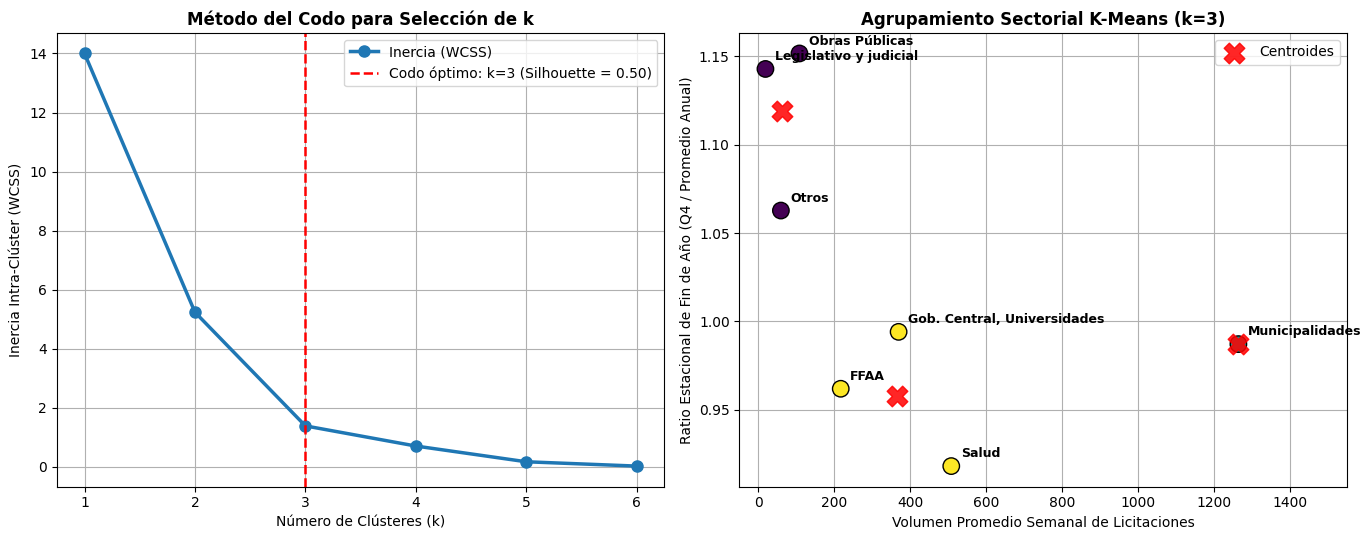

Asignación de Clústeres y Métricas por Sector:


,Volumen_Medio,Ratio_Fin_Anio,Cluster
sector,,,
Legislativo y judicial,18.465,1.143,0
Obras Públicas,108.032,1.152,0
Otros,59.185,1.063,0
Municipalidades,1264.312,0.987,1
FFAA,216.796,0.962,2
"Gob. Central, Universidades",369.255,0.994,2
Salud,507.955,0.918,2


In [4]:
# 1. Construir matriz con las 2 dimensiones clave del negocio: Escala Histórica vs. Estacionalidad de Calendario
features = pd.DataFrame(index=P.columns)
features["Volumen_Medio"] = P.mean(axis=0)
features["Ratio_Fin_Anio"] = P_fechas[P_fechas.index.month.isin([10, 11, 12])].mean(axis=0) / P.mean(axis=0)

# Estandarizar variables
scaler = StandardScaler()
X = scaler.fit_transform(features)

# 2. Evaluar desde k=1 hasta k=6 para visualizar el quiebre real del Método del Codo
K_range = range(1, 7)
inertias = []
silhouettes = {}

for k_val in K_range:
    km_temp = KMeans(n_clusters=k_val, n_init=20, random_state=42)
    lbls = km_temp.fit_predict(X)
    inertias.append(km_temp.inertia_)
    if 2 <= k_val <= 5:
        silhouettes[k_val] = silhouette_score(X, lbls)

# 3. Entrenar modelo final en el punto óptimo (k=3)
k = 3
km = KMeans(n_clusters=k, n_init=20, random_state=42)
features["Cluster"] = km.fit_predict(X)
centroides_originales = scaler.inverse_transform(km.cluster_centers_)

# Graficar Método del Codo y Mapa de Clústeres
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel Izquierdo: Método del Codo con quiebre claro en k=3
ax1 = axes[0]
ax1.plot(K_range, inertias, marker='o', markersize=8, color='tab:blue', lw=2.5, label='Inercia (WCSS)')
ax1.axvline(x=3, color='red', linestyle='--', lw=1.8, label=f'Codo óptimo: k=3 (Silhouette = {silhouettes[3]:.2f})')
ax1.set_title("Método del Codo para Selección de k", fontsize=12, fontweight='bold')
ax1.set_xlabel("Número de Clústeres (k)")
ax1.set_ylabel("Inercia Intra-Clúster (WCSS)")
ax1.set_xticks(list(K_range))
ax1.legend()

# Panel Derecho: Mapa de Clústeres en variables reales (mucho más interpretable que PCA)
ax2 = axes[1]
ax2.scatter(features["Volumen_Medio"], features["Ratio_Fin_Anio"], s=140, c=features["Cluster"], cmap='viridis', edgecolors='k', zorder=3)
ax2.scatter(centroides_originales[:, 0], centroides_originales[:, 1], marker='X', s=220, c='red', alpha=0.85, label='Centroides', zorder=4)

for nombre, row in features.iterrows():
    ax2.annotate(nombre, (row["Volumen_Medio"] + 25, row["Ratio_Fin_Anio"] + 0.005), fontsize=9, fontweight='bold')

ax2.set_title(f"Agrupamiento Sectorial K-Means (k={k})", fontsize=12, fontweight='bold')
ax2.set_xlabel("Volumen Promedio Semanal de Licitaciones")
ax2.set_ylabel("Ratio Estacional de Fin de Año (Q4 / Promedio Anual)")
ax2.set_xlim(-50, 1550)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

# Tabla resumen
print("Asignación de Clústeres y Métricas por Sector:")
display(features.round(3).sort_values("Cluster"))

El agrupamiento revela **3 perfiles operacionales distintos** en el Estado:
* **Clúster 0 (Demanda Estacional de Fin de Año - Escala Baja):** `Obras Públicas`, `Legislativo y judicial` y `Otros` (~186 licitaciones/semana en conjunto), con un incremento relativo durante el último trimestre (`Ratio_Fin_Anio` superior a 1).
* **Clúster 1 (Demanda Masiva Autónoma):** `Municipalidades` (~1.264 licitaciones/semana), que representa el grupo de mayor volumen y mantiene una actividad propia.
* **Clúster 2 (Demanda Institucional Estable - Escala Media/Alta):** `Salud`, `Gob. Central, Universidades` y `FFAA` (~1.094 licitaciones/semana en conjunto), con un volumen alto de actividad.

**Calidad del agrupamiento:** la inercia del método del codo cae de ~14 (k=1) a ~5,2 (k=2) y ~1,4 (k=3), y desde k=4 la mejora es marginal, por lo que k=3 equilibra simplicidad y ajuste. El silhouette de 0,50 indica una separación moderada, razonable para solo 7 observaciones (sectores).

La separación proviene sobre todo de la escala de volumen: `Municipalidades` publica ~2,5 veces más que el sector que le sigue (`Salud`, ~508 licitaciones/semana) y queda aislada en su propio clúster. La estacionalidad de fin de año distingue al Clúster 0 (`Ratio_Fin_Anio` entre 1,06 y 1,15) del resto de los sectores (entre 0,92 y 0,99). Al ser pocos sectores, el cambio de un solo sector de grupo alteraría la estructura, por lo que el agrupamiento debe leerse como una segmentación descriptiva y no como una partición definitiva.

Los nombres y la composición de los clústeres se mantienen asociados a las etiquetas generadas por K-Means en el resto del notebook.

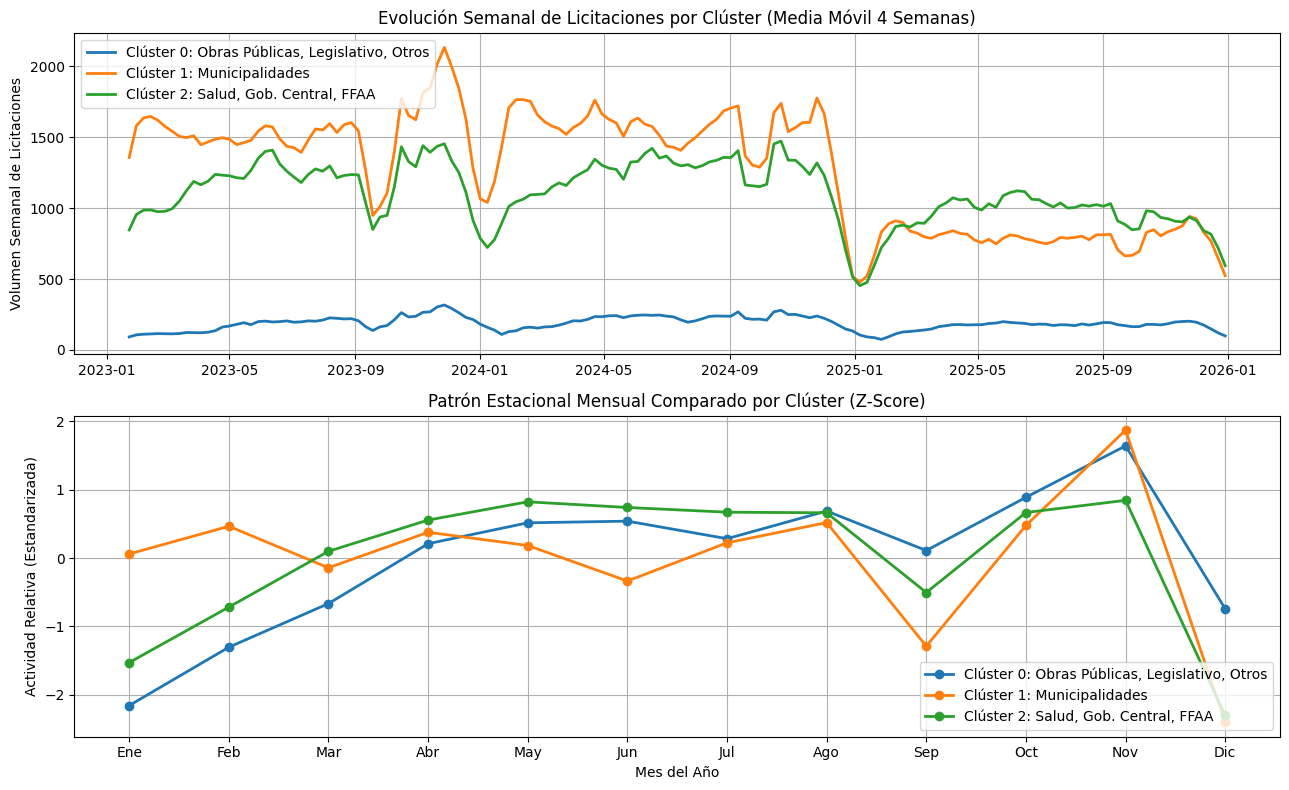

In [5]:
nombres_cluster = {
    0: "Clúster 0: Obras Públicas, Legislativo, Otros",
    1: "Clúster 1: Municipalidades",
    2: "Clúster 2: Salud, Gob. Central, FFAA"
}
colores = {0: "tab:blue", 1: "tab:orange", 2: "tab:green"}

# Construir DataFrame con las series semanales sumadas por Clúster
series_cluster = pd.DataFrame(index=P_fechas.index)
for c in range(k):
    sectores_c = features[features["Cluster"] == c].index
    series_cluster[c] = P_fechas[sectores_c].sum(axis=1)

series_cluster = series_cluster.asfreq("W-MON").fillna(0)

# Graficar series semanales (Media Móvil 4 semanas) y Perfil Estacional Mensual por Clúster
fig, axes = plt.subplots(2, 1, figsize=(13, 8))

# Gráfico 1: Evolución Semanal (Media Móvil 4 semanas) en volumen real
for c in range(k):
    mm4 = series_cluster[c].rolling(window=4).mean()
    axes[0].plot(series_cluster.index, mm4, lw=2, color=colores[c], label=nombres_cluster[c])

axes[0].set_title("Evolución Semanal de Licitaciones por Clúster (Media Móvil 4 Semanas)")
axes[0].set_ylabel("Volumen Semanal de Licitaciones")
axes[0].legend(loc="upper left")

# Gráfico 2: Comportamiento Estacional según Mes del Año (Estandarizado para comparar la forma del ciclo)
perfil_mensual = series_cluster.groupby(series_cluster.index.month).mean()
perfil_mensual_norm = pd.DataFrame(
    StandardScaler().fit_transform(perfil_mensual),
    index=perfil_mensual.index,
    columns=perfil_mensual.columns
)

meses_nombres = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
for c in range(k):
    axes[1].plot(range(1, 13), perfil_mensual_norm[c], marker='o', lw=2, color=colores[c], label=nombres_cluster[c])

axes[1].set_title("Patrón Estacional Mensual Comparado por Clúster (Z-Score)")
axes[1].set_xlabel("Mes del Año")
axes[1].set_ylabel("Actividad Relativa (Estandarizada)")
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(meses_nombres)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

Las series de los tres clústeres comparten un calendario común: caídas en septiembre y entre diciembre y enero, y un máximo en noviembre (probablemente asociados a Fiestas Patrias, vacaciones de verano y cierre del ejercicio presupuestario). Además se observa un **quiebre de nivel a comienzos de 2025**: `Municipalidades` baja de ~1.500–1.700 a ~800 licitaciones semanales, el Clúster 2 pasa de ~1.300 a ~1.000 aproximadamente y el Clúster 0 se mantiene casi estable en torno a ~200. Este cambio estructural es relevante para las etapas siguientes, porque afecta la estacionariedad y el error de pronóstico del clúster de mayor volumen.

## 3. Descomposición Temporal y Diagnóstico para Fase 2 (ARIMA / SARIMA)
Para configurar los modelos predictivos de la Entrega Final, evaluamos la descomposición de la serie agregada (Tendencia, Estacionalidad y Residuo), verificamos la **estacionariedad mediante el test de Dickey-Fuller Aumentado (ADF)** en cada clúster y analizamos las funciones de **Autocorrelación (ACF y PACF)**.

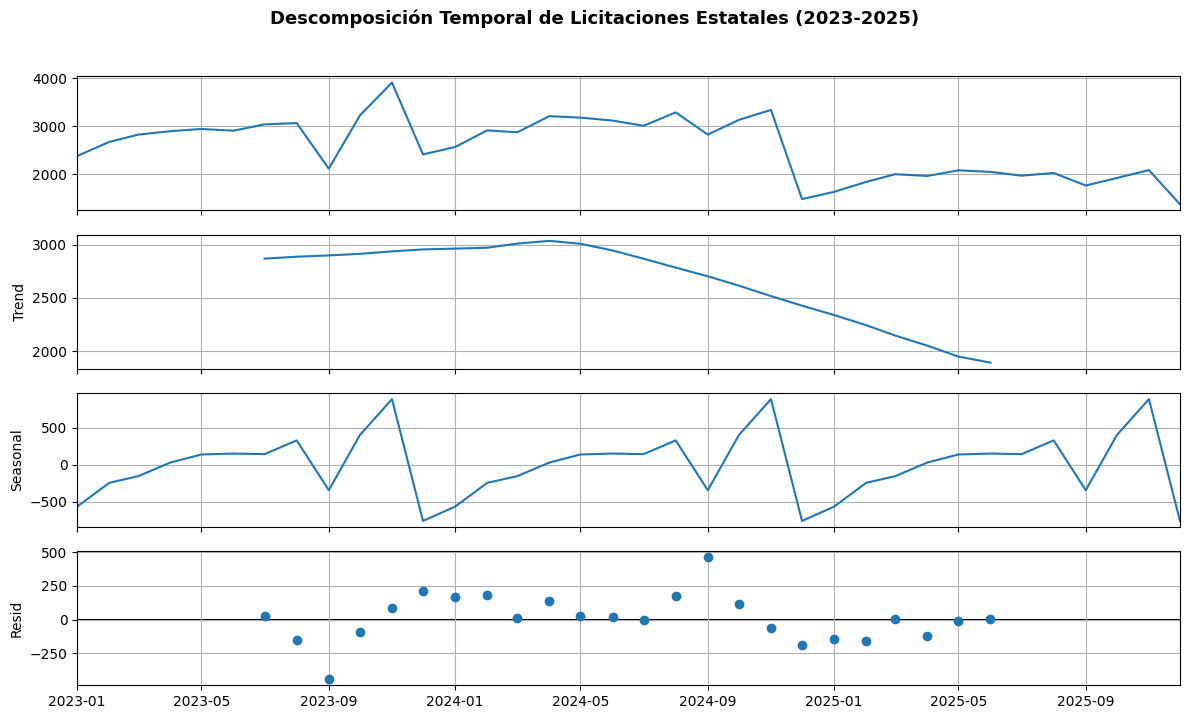

=== Diagnóstico de Estacionariedad (Test ADF) por Clúster ===


,Clúster,Volumen_Promedio_Semanal,ADF_Statistic,p-value,Estacionaria (alpha=0.05)
0,"Clúster 0: Obras Públicas, Legislativo, Otros",185.7,-3.301,0.0148,Sí (d=0)
1,Clúster 1: Municipalidades,1264.3,-0.830,0.8100,No (Requiere diferenciación d>=1)
2,"Clúster 2: Salud, Gob. Central, FFAA",1094.0,-3.441,0.0097,Sí (d=0)


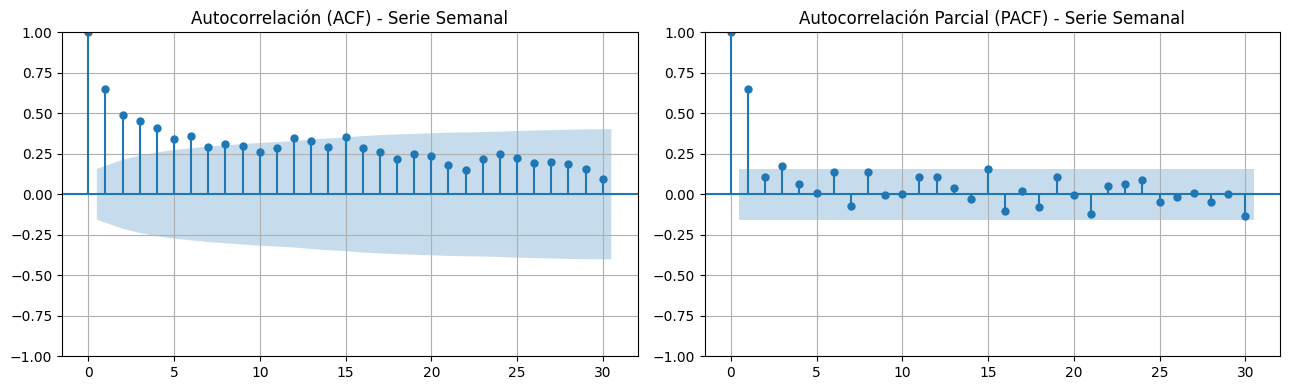

In [6]:
# 1. Serie agregada mensual para descomposición macro (Tendencia + Estacionalidad anual)
lic_total = series_cluster.sum(axis=1)
serie_mensual = lic_total.resample("MS").mean()

resultado_sd = seasonal_decompose(serie_mensual, model="additive", period=12)
fig = resultado_sd.plot()
fig.set_size_inches(12, 7)
plt.suptitle("Descomposición Temporal de Licitaciones Estatales (2023-2025)", y=1.02, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Test de Estacionariedad (Dickey-Fuller Aumentado) por Clúster
print("=== Diagnóstico de Estacionariedad (Test ADF) por Clúster ===")
resultados_adf = []
for c in range(k):
    stat, p_val, _, _, _, _ = adfuller(series_cluster[c].dropna())
    es_estacionaria = "Sí (d=0)" if p_val < 0.05 else "No (Requiere diferenciación d>=1)"
    resultados_adf.append({
        "Clúster": nombres_cluster[c],
        "Volumen_Promedio_Semanal": round(series_cluster[c].mean(), 1),
        "ADF_Statistic": round(stat, 3),
        "p-value": round(p_val, 4),
        "Estacionaria (alpha=0.05)": es_estacionaria
    })
display(pd.DataFrame(resultados_adf))

# 3. Gráficos de Autocorrelación (ACF y PACF) para parametrizar ARIMA/SARIMA en la Fase 2
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(lic_total.dropna(), lags=30, ax=axes[0], title="Autocorrelación (ACF) - Serie Semanal")
plot_pacf(lic_total.dropna(), lags=30, ax=axes[1], title="Autocorrelación Parcial (PACF) - Serie Semanal")
plt.tight_layout()
plt.show()

El diagnóstico ADF permite distinguir el comportamiento temporal de cada clúster. Un p-value menor a 0.05 indica evidencia para considerar la serie estacionaria; un valor mayor o igual a 0.05 indica que no se rechaza la hipótesis de raíz unitaria y que puede ser necesario diferenciar la serie.

**Resultados del ADF.** En la serie completa, los Clústeres 0 (p = 0,0148) y 2 (p = 0,0097) son estacionarios, mientras que el Clúster 1 (`Municipalidades`, p = 0,81) no lo es. Esto es coherente con el quiebre de nivel de 2025: el ADF tiene poca potencia frente a cambios estructurales y tiende a no rechazar la raíz unitaria. Al repetir el test solo con las 133 semanas de entrenamiento (sección 4.1), el Clúster 1 resulta estacionario (p = 0,0001), por lo que los cuatro modelos finales (tres clústeres y serie global) se ajustaron con `d = 0`.

**Descomposición y autocorrelación.** La serie mensual agregada muestra una media semanal estable en torno a 3.000 licitaciones hasta mediados de 2024 y una caída posterior hacia ~1.900, con un patrón estacional anual muy marcado: máximo en noviembre y mínimos en diciembre, enero y septiembre. La ACF decae lentamente (≈0,65 en el rezago 1) y la PACF se corta tras el primer rezago, lo que sugiere una dependencia autorregresiva de orden bajo. Esto justifica probar combinaciones ARIMA de orden bajo y, sobre todo, incorporar estacionalidad anual mediante SARIMA con período 52.

## 4. Modelos Predictivos por Clúster y Baseline Global

A partir del diagnóstico anterior, se entrenan y evalúan modelos de pronóstico **por separado para cada clúster**. De esta forma, cada modelo utiliza el comportamiento temporal propio de los sectores que componen el grupo. Como referencia (baseline) se entrenan además los mismos modelos sobre una **serie global** que suma todos los sectores, sin utilizar K-Means.

Se mantiene el mismo enfoque del análisis de series de tiempo:
* **ARIMA:** se prueban distintas combinaciones de parámetros \\(p,d,q\\). El valor de diferenciación `d` se define según el diagnóstico ADF de cada clúster.
* **Auto ARIMA:** selecciona automáticamente los parámetros que mejor se ajustan a los datos de entrenamiento.
* **SARIMA:** incorpora un componente estacional anual, utilizando un período de 52 semanas.
* **Prophet:** permite modelar tendencia y estacionalidad anual.

Para comparar los modelos, se reservan las últimas **24 semanas**: **12 de validación** (para elegir el modelo) y **12 de prueba** (para informar el error final). Se utilizan las métricas MAE, RMSE y MAPE. Un menor valor en estas métricas representa un menor error de predicción.

In [7]:
# Baseline sin clústeres: serie global con todos los sectores
serie_global = P_fechas.sum(axis=1).asfreq("W-MON").fillna(0)

series_modelo = {c: series_cluster[c] for c in range(k)}
series_modelo[k] = serie_global
nombres_cluster[k] = "Global: todos los sectores (sin K-Means)"


In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

try:
    import pmdarima as pm
except ImportError:
    pm = None

try:
    from prophet import Prophet
except ImportError:
    Prophet = None

def evaluar(val, test, pred):
    resultados = {}
    for etiqueta, real in [("Val", val), ("Test", test)]:
        p = pred.loc[real.index]
        resultados[f"MAE_{etiqueta}"] = mean_absolute_error(real, p)
        resultados[f"RMSE_{etiqueta}"] = np.sqrt(mean_squared_error(real, p))
        resultados[f"MAPE_{etiqueta}"] = mean_absolute_percentage_error(real, p) * 100
    return resultados

# Separacion entrenamiento, validacion y prueba para cada clúster y para la serie global
train_cluster = {}
val_cluster = {}
test_cluster = {}

for c in range(k + 1):
    train_cluster[c] = series_modelo[c].iloc[:-24]
    val_cluster[c] = series_modelo[c].iloc[-24:-12]
    test_cluster[c] = series_modelo[c].iloc[-12:]

    print(nombres_cluster[c])
    print("Entrenamiento:", len(train_cluster[c]))
    print("Validacion:", len(val_cluster[c]))
    print("Prueba:", len(test_cluster[c]))
    print()



Clúster 0: Obras Públicas, Legislativo, Otros
Entrenamiento: 133
Validacion: 12
Prueba: 12

Clúster 1: Municipalidades
Entrenamiento: 133
Validacion: 12
Prueba: 12

Clúster 2: Salud, Gob. Central, FFAA
Entrenamiento: 133
Validacion: 12
Prueba: 12

Global: todos los sectores (sin K-Means)
Entrenamiento: 133
Validacion: 12
Prueba: 12



### 4.1 Entrenamiento y evaluación

Se evalúan los cuatro modelos sobre los mismos períodos de validación y prueba (las 24 semanas posteriores al entrenamiento) para que la comparación sea equivalente. En ARIMA y SARIMA se utiliza el resultado del test ADF para definir si la serie requiere diferenciación (`d=0` o `d=1`).

In [9]:
resultados_modelos = []
predicciones_cluster = {}

for c in range(k + 1):
    train = train_cluster[c]
    val = val_cluster[c]
    test = test_cluster[c]
    horizonte = val.index.append(test.index)
    predicciones_cluster[c] = {}

    # Test ADF para definir el orden de diferenciacion
    stat, p_val, _, _, _, _ = adfuller(train.dropna())
    d = 0 if p_val < 0.05 else 1

    print("=" * 70)
    print(nombres_cluster[c])
    print("ADF p-value:", round(p_val, 4), "| Diferenciacion utilizada (d):", d)

    # ARIMA
    modelos_arima = [
        (1, d, 0),
        (2, d, 0),
        (1, d, 1),
        (2, d, 1)
    ]

    for orden in modelos_arima:
        try:
            modelo = ARIMA(train, order=orden).fit()
            pred = modelo.forecast(steps=len(horizonte))
            pred = pd.Series(np.asarray(pred), index=horizonte)

            resultados_modelos.append({
                "Cluster": nombres_cluster[c],
                "Modelo": f"ARIMA{orden}",
                "AIC": modelo.aic,
                **evaluar(val, test, pred)
            })
            predicciones_cluster[c][f"ARIMA{orden}"] = pred
        except Exception as e:
            print("No fue posible ajustar ARIMA", orden, ":", e)

    # Auto ARIMA
    if pm is not None:
        try:
            modelo_auto = pm.auto_arima(
                train,
                d=d,
                seasonal=False,
                stepwise=True,
                suppress_warnings=True,
                error_action="ignore"
            )
            pred_auto = pd.Series(
                modelo_auto.predict(n_periods=len(horizonte)),
                index=horizonte
            )

            resultados_modelos.append({
                "Cluster": nombres_cluster[c],
                "Modelo": f"Auto ARIMA{modelo_auto.order}",
                "AIC": modelo_auto.aic(),
                **evaluar(val, test, pred_auto)
            })
            predicciones_cluster[c][f"Auto ARIMA{modelo_auto.order}"] = pred_auto
        except Exception as e:
            print("No fue posible ajustar Auto ARIMA:", e)
    else:
        print("Auto ARIMA omitido: instalar pmdarima para utilizar este modelo.")

    # SARIMA con estacionalidad anual (52 semanas)
    modelos_sarima = [
        ((1, d, 0), (1, 0, 0, 52)),
        ((1, d, 1), (1, 0, 0, 52)),
        ((2, d, 1), (1, 0, 0, 52))
    ]

    for orden, estacional in modelos_sarima:
        try:
            modelo = SARIMAX(
                train,
                order=orden,
                seasonal_order=estacional,
                enforce_stationarity=False,
                enforce_invertibility=False
            ).fit(disp=False)

            pred = modelo.forecast(steps=len(horizonte))
            pred = pd.Series(np.asarray(pred), index=horizonte)

            resultados_modelos.append({
                "Cluster": nombres_cluster[c],
                "Modelo": f"SARIMA{orden}{estacional}",
                "AIC": modelo.aic,
                **evaluar(val, test, pred)
            })
            predicciones_cluster[c][f"SARIMA{orden}{estacional}"] = pred
        except Exception as e:
            print("No fue posible ajustar SARIMA", orden, estacional, ":", e)

    # Prophet
    if Prophet is not None:
        try:
            train_prophet = train.reset_index()
            train_prophet.columns = ["ds", "y"]

            modelo_prophet = Prophet(
                yearly_seasonality=True,
                weekly_seasonality=False,
                daily_seasonality=False
            )
            modelo_prophet.fit(train_prophet)

            futuro = modelo_prophet.make_future_dataframe(
                periods=len(horizonte),
                freq="W-MON"
            )
            predicciones = modelo_prophet.predict(futuro)
            pred_prophet = predicciones.set_index("ds").loc[horizonte, "yhat"]

            resultados_modelos.append({
                "Cluster": nombres_cluster[c],
                "Modelo": "Prophet",
                "AIC": np.nan,
                **evaluar(val, test, pred_prophet)
            })
            predicciones_cluster[c]["Prophet"] = pred_prophet
        except Exception as e:
            print("No fue posible ajustar Prophet:", e)
    else:
        print("Prophet omitido: instalar prophet para utilizar este modelo.")

# Tabla comparativa de todos los modelos y clústeres
df_modelos = pd.DataFrame(resultados_modelos)
df_modelos = df_modelos.sort_values(["Cluster", "RMSE_Val"]).reset_index(drop=True)

display(df_modelos.round(2))


Clúster 0: Obras Públicas, Legislativo, Otros
ADF p-value: 0.0212 | Diferenciacion utilizada (d): 0
Clúster 1: Municipalidades
ADF p-value: 0.0001 | Diferenciacion utilizada (d): 0
Clúster 2: Salud, Gob. Central, FFAA
ADF p-value: 0.0029 | Diferenciacion utilizada (d): 0
Global: todos los sectores (sin K-Means)
ADF p-value: 0.0094 | Diferenciacion utilizada (d): 0


,Cluster,Modelo,AIC,MAE_Val,RMSE_Val,MAPE_Val,MAE_Test,RMSE_Test,MAPE_Test
0,"Clúster 0: Obras Públicas, Legislativo, Otros","SARIMA(2, 0, 1)(1, 0, 0, 52)",835.71,16.68,18.65,9.36,28.05,33.76,24.35
1,"Clúster 0: Obras Públicas, Legislativo, Otros","SARIMA(1, 0, 1)(1, 0, 0, 52)",844.85,16.90,18.68,9.51,27.76,33.88,24.49
2,"Clúster 0: Obras Públicas, Legislativo, Otros","ARIMA(1, 0, 1)",1432.74,20.11,28.00,12.65,39.85,52.96,38.83
3,"Clúster 0: Obras Públicas, Legislativo, Otros","Auto ARIMA(1, 0, 1)",1432.74,20.11,28.00,12.65,39.85,52.95,38.83
4,"Clúster 0: Obras Públicas, Legislativo, Otros","ARIMA(2, 0, 1)",1434.65,20.18,28.05,12.68,39.83,52.91,38.79
5,"Clúster 0: Obras Públicas, Legislativo, Otros","ARIMA(2, 0, 0)",1439.08,19.52,28.42,12.70,40.52,54.79,40.21
6,"Clúster 0: Obras Públicas, Legislativo, Otros","ARIMA(1, 0, 0)",1442.51,19.90,28.98,13.10,40.71,55.33,40.57
7,"Clúster 0: Obras Públicas, Legislativo, Otros",Prophet,NaN,31.33,36.20,18.41,40.91,48.80,31.10
8,"Clúster 0: Obras Públicas, Legislativo, Otros","SARIMA(1, 0, 0)(1, 0, 0, 52)",870.52,51.41,55.91,27.87,77.73,85.18,45.63
9,Clúster 1: Municipalidades,"SARIMA(1, 0, 0)(1, 0, 0, 52)",1127.78,57.89,72.39,8.88,146.25,178.27,24.12


### 4.2 Comparación de pronósticos por clúster

Se grafican los valores reales de los conjuntos de validación y prueba junto a las predicciones obtenidas por cada modelo. Esto permite observar visualmente qué tan bien se ajusta cada pronóstico al comportamiento real de cada grupo.

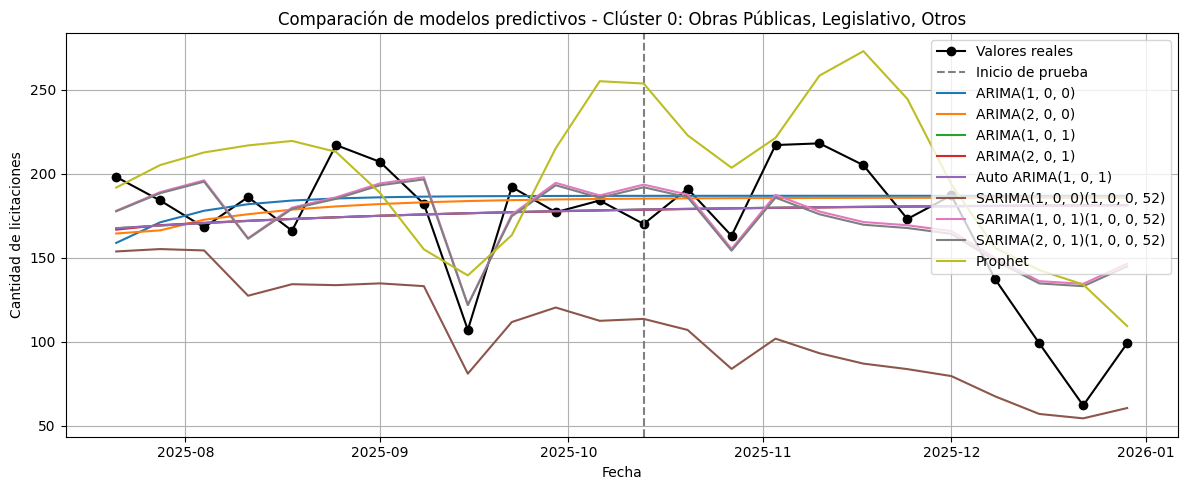

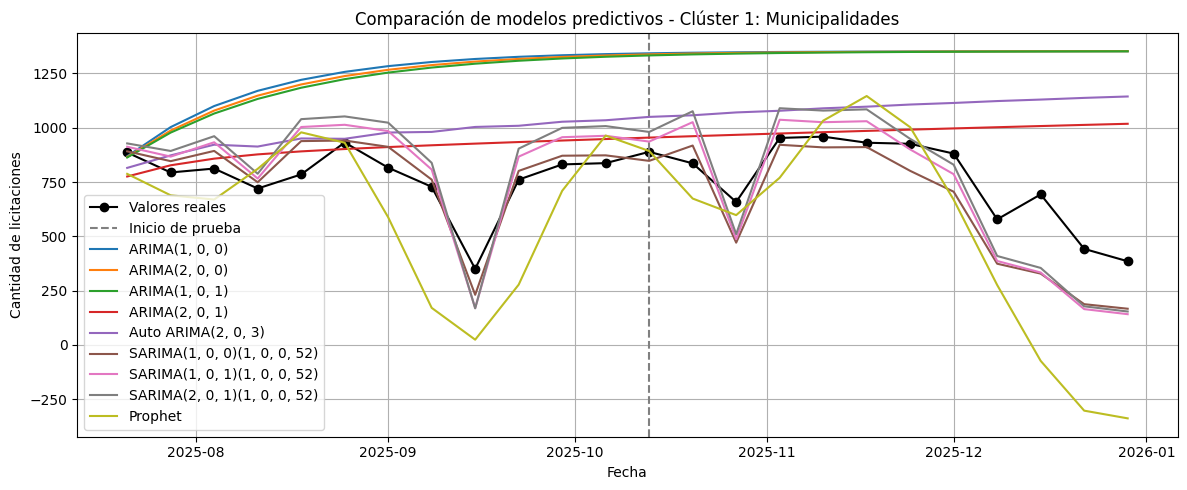

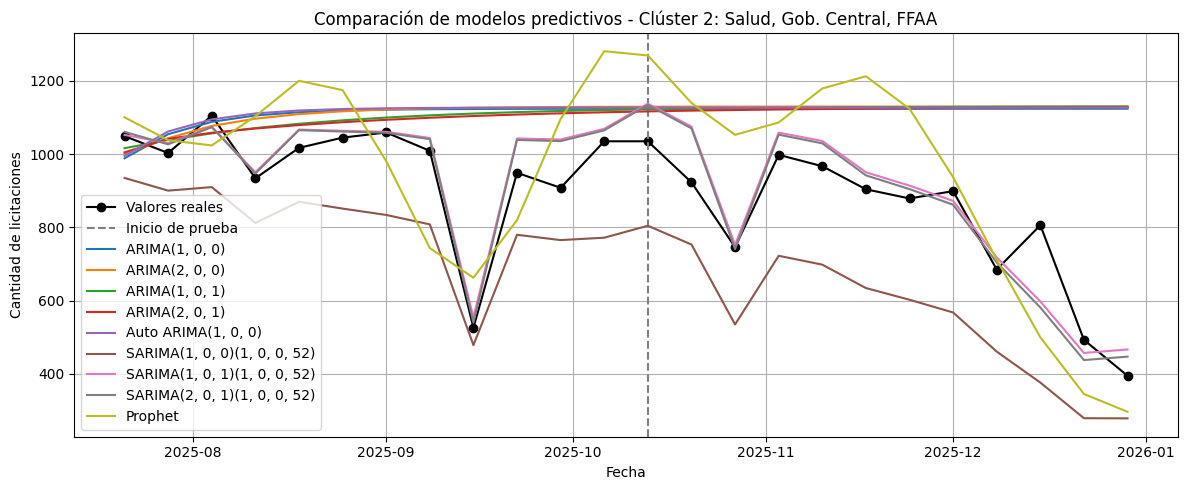

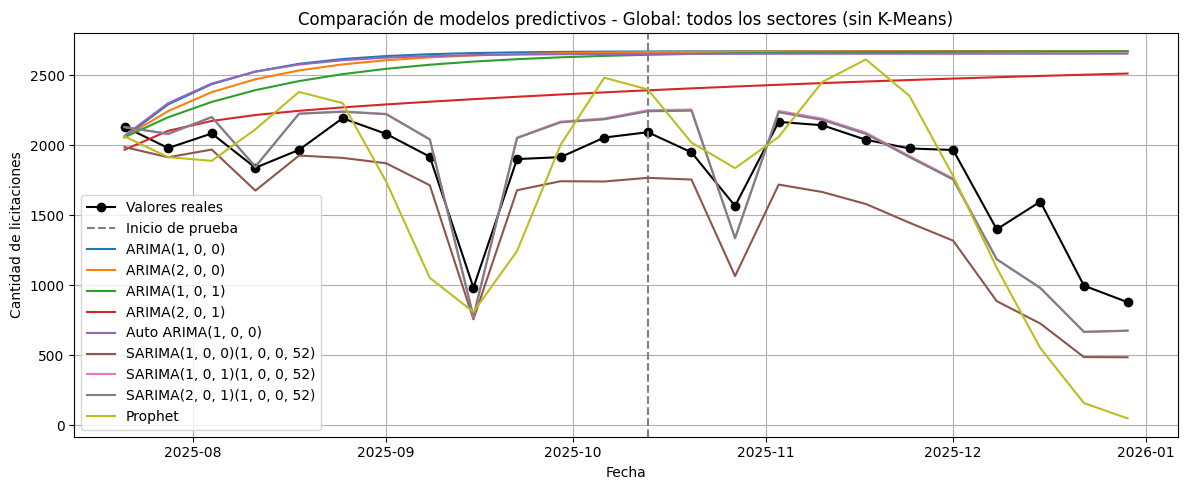

In [10]:
for c in range(k + 1):
    real = pd.concat([val_cluster[c], test_cluster[c]])

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(real.index, real.values, label="Valores reales", color="black", marker="o")
    ax.axvline(test_cluster[c].index[0], color="gray", linestyle="--", label="Inicio de prueba")

    for nombre, pred in predicciones_cluster[c].items():
        ax.plot(pred.index, pred.values, label=nombre)

    ax.set_title("Comparación de modelos predictivos - " + nombres_cluster[c])
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Cantidad de licitaciones")
    ax.legend()

    plt.tight_layout()
    plt.show()
    plt.close(fig)


### 4.3 Selección del mejor modelo

Se selecciona el modelo con menor RMSE en el conjunto de **validación** para cada clúster y para la serie global; las métricas del conjunto de prueba se informan solo para el modelo ya seleccionado. Además de comparar el error, se considera el gráfico de predicciones para revisar si el modelo logra representar la evolución de la serie y no solamente obtener un error bajo.

Clúster 0: Obras Públicas, Legislativo, Otros
Mejor modelo: SARIMA(2, 0, 1)(1, 0, 0, 52)
RMSE validacion: 18.65
MAE prueba: 28.05
RMSE prueba: 33.76
MAPE prueba: 24.35 %


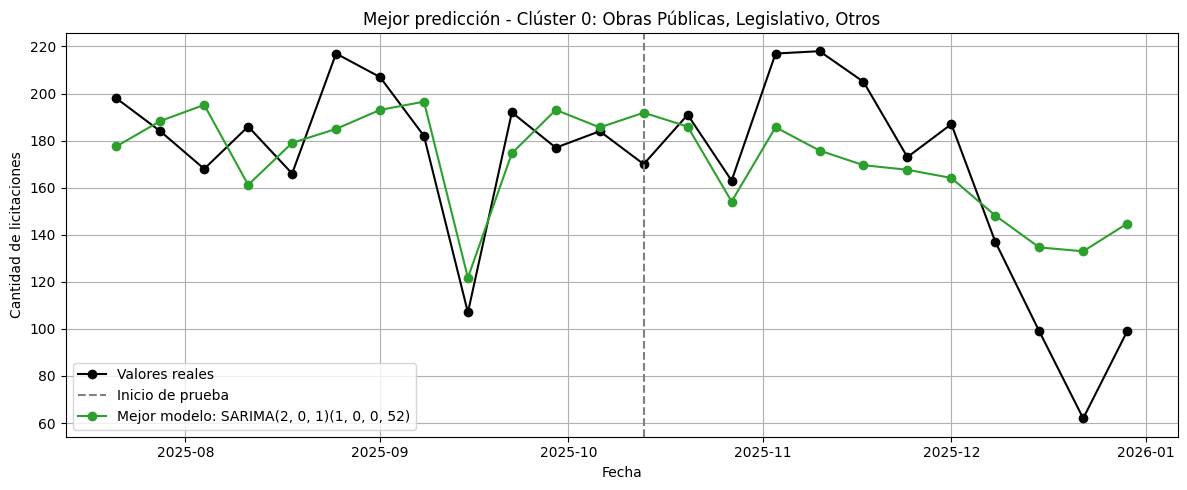

Clúster 1: Municipalidades
Mejor modelo: SARIMA(1, 0, 0)(1, 0, 0, 52)
RMSE validacion: 72.39
MAE prueba: 146.25
RMSE prueba: 178.27
MAPE prueba: 24.12 %


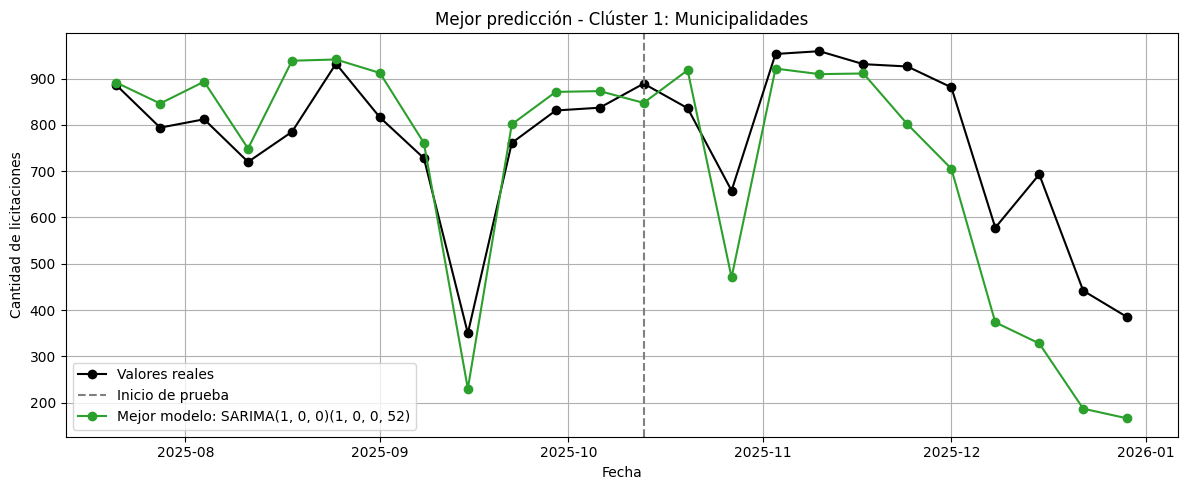

Clúster 2: Salud, Gob. Central, FFAA
Mejor modelo: SARIMA(2, 0, 1)(1, 0, 0, 52)
RMSE validacion: 50.7
MAE prueba: 68.45
RMSE prueba: 90.63
MAPE prueba: 8.71 %


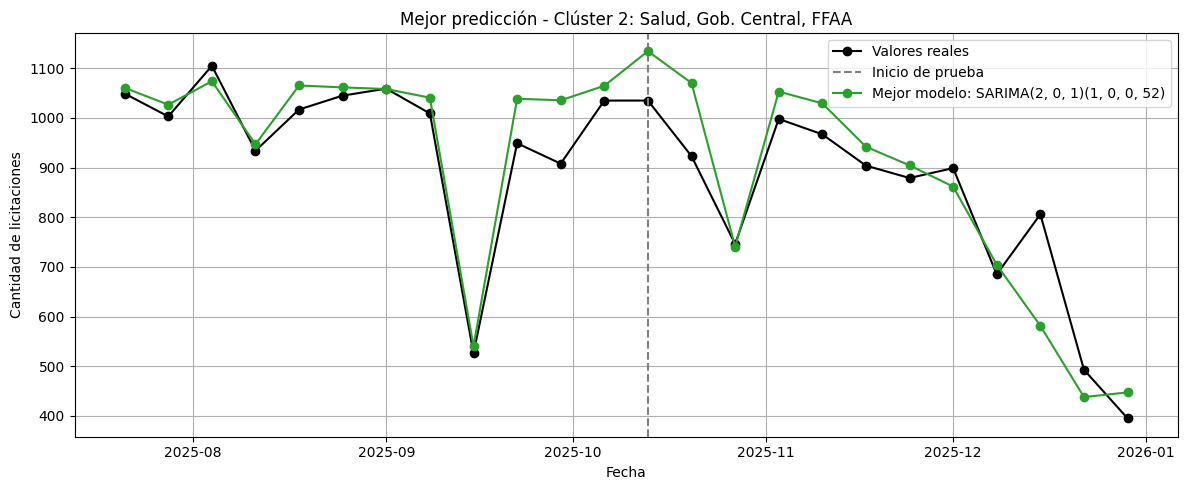

Global: todos los sectores (sin K-Means)
Mejor modelo: SARIMA(2, 0, 1)(1, 0, 0, 52)
RMSE validacion: 150.17
MAE prueba: 205.55
RMSE prueba: 258.01
MAPE prueba: 14.02 %


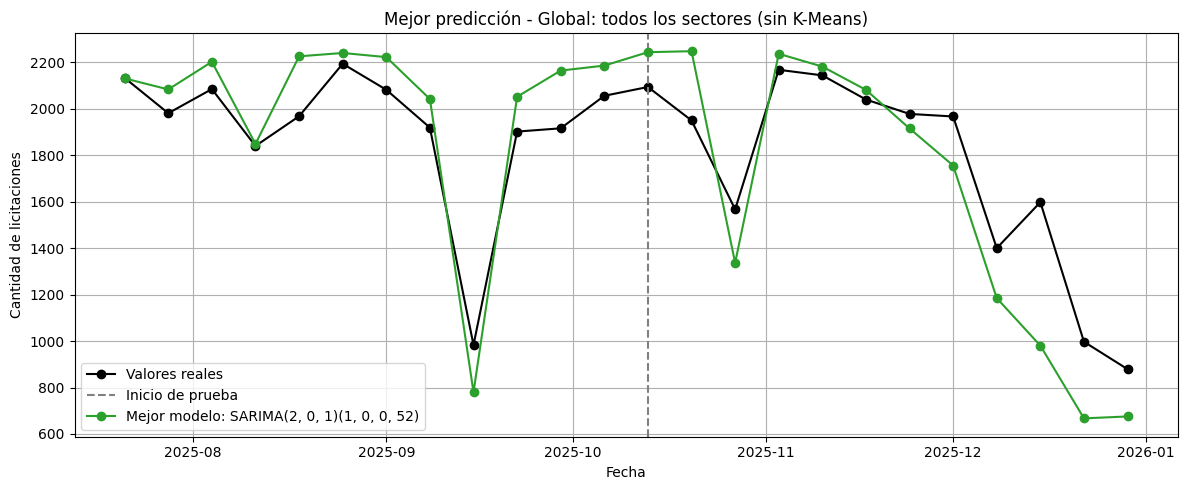

,Cluster,Modelo,RMSE_Val,MAE_Test,RMSE_Test,MAPE_Test
0,"Clúster 0: Obras Públicas, Legislativo, Otros","SARIMA(2, 0, 1)(1, 0, 0, 52)",18.65,28.05,33.76,24.35
9,Clúster 1: Municipalidades,"SARIMA(1, 0, 0)(1, 0, 0, 52)",72.39,146.25,178.27,24.12
18,"Clúster 2: Salud, Gob. Central, FFAA","SARIMA(2, 0, 1)(1, 0, 0, 52)",50.70,68.45,90.63,8.71
27,Global: todos los sectores (sin K-Means),"SARIMA(2, 0, 1)(1, 0, 0, 52)",150.17,205.55,258.01,14.02


In [11]:
mejores_modelos = []

for c in range(k + 1):
    nombre = nombres_cluster[c]
    comparacion = df_modelos[df_modelos["Cluster"] == nombre].sort_values("RMSE_Val")

    if len(comparacion) == 0:
        print("No hay modelos disponibles para", nombre)
        continue

    mejor = comparacion.iloc[0]
    mejores_modelos.append(mejor)

    print("=" * 70)
    print(nombre)
    print("Mejor modelo:", mejor["Modelo"])
    print("RMSE validacion:", round(mejor["RMSE_Val"], 2))
    print("MAE prueba:", round(mejor["MAE_Test"], 2))
    print("RMSE prueba:", round(mejor["RMSE_Test"], 2))
    print("MAPE prueba:", round(mejor["MAPE_Test"], 2), "%")

    # Graficar el mejor modelo del clúster
    pred_mejor = predicciones_cluster[c][mejor["Modelo"]]

    real = pd.concat([val_cluster[c], test_cluster[c]])

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(real.index, real.values,
            label="Valores reales", color="black", marker="o")
    ax.axvline(test_cluster[c].index[0], color="gray", linestyle="--", label="Inicio de prueba")
    ax.plot(pred_mejor.index, pred_mejor.values,
            label="Mejor modelo: " + mejor["Modelo"], color="tab:green", marker="o")

    ax.set_title("Mejor predicción - " + nombre)
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Cantidad de licitaciones")
    ax.legend()

    plt.tight_layout()
    plt.show()
    plt.close(fig)

df_mejores_modelos = pd.DataFrame(mejores_modelos)
display(df_mejores_modelos[["Cluster", "Modelo", "RMSE_Val", "MAE_Test", "RMSE_Test", "MAPE_Test"]].round(2))


### 4.4 Análisis de resultados

La tabla anterior permite identificar el modelo que presenta el menor error de validación para cada clúster y para la serie global. La comparación debe interpretarse considerando que los grupos tienen escalas de volumen diferentes: por esta razón, MAE y RMSE se expresan en cantidad de licitaciones y pueden ser mayores en clústeres con más actividad. El MAPE permite complementar la comparación mediante un error porcentual.

**Modelo seleccionado por validación y desempeño en prueba:**

| Serie | Modelo seleccionado | RMSE validación | MAE prueba | RMSE prueba | MAPE prueba |
|---|---|---|---|---|---|
| Clúster 0: Obras Públicas, Legislativo, Otros | SARIMA(2,0,1)(1,0,0,52) | 18,65 | 28,05 | 33,76 | 24,35 % |
| Clúster 1: Municipalidades | SARIMA(1,0,0)(1,0,0,52) | 72,39 | 146,25 | 178,27 | 24,12 % |
| Clúster 2: Salud, Gob. Central, FFAA | SARIMA(2,0,1)(1,0,0,52) | 50,70 | 68,45 | 90,63 | 8,71 % |
| Global (sin K-Means) | SARIMA(2,0,1)(1,0,0,52) | 150,17 | 205,55 | 258,01 | 14,02 % |

* **La estacionalidad anual es el factor decisivo.** SARIMA con período 52 fue el mejor modelo en validación en las cuatro series y también obtuvo el menor RMSE de prueba (en el Clúster 2 empata prácticamente con SARIMA(1,0,1): 89,94 vs. 90,63). Los ARIMA sin componente estacional y Prophet quedan claramente por detrás: en el Clúster 2, por ejemplo, el MAPE de prueba es 8,7 % para el SARIMA seleccionado, 23,4 % para Prophet y ~50 % para los ARIMA. Probablemente esto se debe a que las caídas abruptas de septiembre y diciembre no pueden representarse con un modelo sin estacionalidad, y Prophet, con menos de tres años de historia, las suaviza.
* **El Clúster 2 es el más predecible** (MAPE de prueba 8,7 %). En los Clústeres 0 y 1 el MAPE ronda el 24 %: el Clúster 0 tiene bajo volumen, por lo que cualquier desviación pesa más en términos porcentuales, y en el Clúster 1 el modelo reproduce la caída de diciembre de años anteriores pero la subestima en las últimas semanas del año (el nivel base de 2025 es más bajo y el descenso observado fue menos profundo).
* **El error aumenta de validación a prueba** en todas las series, algo esperable porque la prueba está más lejos del fin del entrenamiento (semanas 13 a 24 del pronóstico) y contiene el cierre de año. El RMSE de validación, por lo tanto, subestima el error real; aun así, el modelo elegido en validación fue también el mejor en prueba, lo que respalda el procedimiento de selección.
* **Alcance:** con ~2,5 años de datos el período estacional de 52 semanas se estima a partir de muy pocos ciclos y la prueba corresponde a una sola ventana de 12 semanas, por lo que los resultados deben considerarse preliminares.

## 5. Comparación: Modelo Global vs. Suma de Clústeres

Se compara el error del mejor modelo entrenado sobre la serie global (sin K-Means) contra el error de la suma de las predicciones de los tres clústeres, usando en cada clúster su mejor modelo según validación. Ambos enfoques se evalúan sobre la misma serie real (total de licitaciones) y los mismos períodos de validación y prueba.

,Enfoque,Modelo,MAE_Val,RMSE_Val,MAPE_Val,MAE_Test,RMSE_Test,MAPE_Test
0,Modelo global (sin clústeres),"SARIMA(2, 0, 1)(1, 0, 0, 52)",127.57,150.17,7.30,205.55,258.01,14.02
1,Suma de 3 clústeres,Mejor modelo de cada clúster,84.49,104.45,4.67,165.61,218.59,11.06


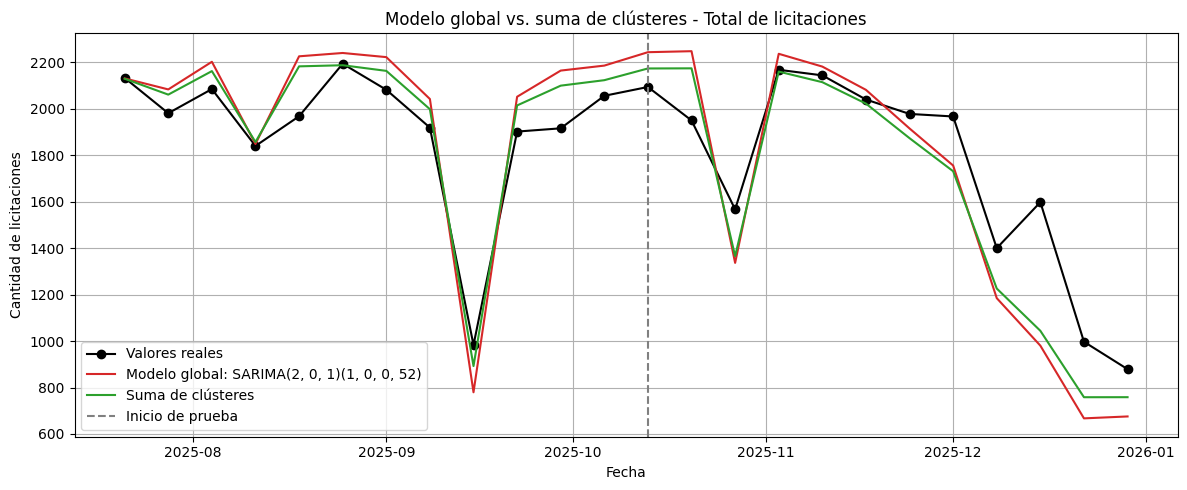

Menor RMSE en prueba: Suma de 3 clústeres


In [12]:
mejor_global = df_mejores_modelos[df_mejores_modelos["Cluster"] == nombres_cluster[k]].iloc[0]
pred_global = predicciones_cluster[k][mejor_global["Modelo"]]

pred_suma = 0
for c in range(k):
    mejor = df_mejores_modelos[df_mejores_modelos["Cluster"] == nombres_cluster[c]].iloc[0]
    pred_suma = pred_suma + predicciones_cluster[c][mejor["Modelo"]]

comparacion_enfoques = pd.DataFrame([
    {"Enfoque": "Modelo global (sin clústeres)", "Modelo": mejor_global["Modelo"],
     **evaluar(val_cluster[k], test_cluster[k], pred_global)},
    {"Enfoque": "Suma de 3 clústeres", "Modelo": "Mejor modelo de cada clúster",
     **evaluar(val_cluster[k], test_cluster[k], pred_suma)}
])
display(comparacion_enfoques.round(2))

real = pd.concat([val_cluster[k], test_cluster[k]])

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(real.index, real.values, label="Valores reales", color="black", marker="o")
ax.plot(pred_global.index, pred_global.values, label="Modelo global: " + mejor_global["Modelo"], color="tab:red")
ax.plot(pred_suma.index, pred_suma.values, label="Suma de clústeres", color="tab:green")
ax.axvline(test_cluster[k].index[0], color="gray", linestyle="--", label="Inicio de prueba")

ax.set_title("Modelo global vs. suma de clústeres - Total de licitaciones")
ax.set_xlabel("Fecha")
ax.set_ylabel("Cantidad de licitaciones")
ax.legend()

plt.tight_layout()
plt.show()
plt.close(fig)

print("Menor RMSE en prueba:", comparacion_enfoques.sort_values("RMSE_Test").iloc[0]["Enfoque"])


**Resultado.** La suma de los tres clústeres obtiene menor error que el modelo global en todas las métricas y en ambos conjuntos:

| Métrica | Modelo global | Suma de clústeres | Reducción del error |
|---|---|---|---|
| RMSE prueba | 258,01 | 218,59 | 15,3 % |
| MAE prueba | 205,55 | 165,61 | 19,4 % |
| MAPE prueba | 14,02 % | 11,06 % | 21,1 % (3,0 p.p.) |
| RMSE validación | 150,17 | 104,45 | 30,4 % |

Modelar cada clúster por separado permite que cada uno use su propia dinámica (la escala y el nivel de `Municipalidades`, la estabilidad del grupo institucional y el sesgo de fin de año del Clúster 0), mientras que un único SARIMA global debe promediarlas. En el gráfico, ambos enfoques siguen el mínimo de septiembre y la recuperación de noviembre, pero el modelo global sobreestima más el nivel de las semanas estables y subestima más la caída de diciembre. La mejora es consistente en validación y prueba, aunque menor en prueba.

**Limitaciones:** la comparación se basa en una única ventana de 12 semanas que incluye el cierre de año, y la diferencia no fue evaluada con un test estadístico de precisión predictiva. Aun así, la evidencia favorece el enfoque con K-Means, que se utiliza en la función de pronóstico final.

## 6. Análisis de Causalidad de Granger entre Clústeres

Se evalúa si el pasado de la serie semanal de un clúster ayuda a predecir la serie de otro clúster. Como el test requiere series estacionarias, se aplica una diferenciación a los clústeres que no son estacionarios según el test ADF. El número de rezagos se selecciona con el criterio AIC de un modelo VAR sobre los tres clústeres.

In [13]:
from statsmodels.tsa.stattools import grangercausalitytests
from statsmodels.tsa.api import VAR

series_granger = pd.DataFrame(index=series_cluster.index)
for c in range(k):
    p_val = adfuller(series_cluster[c].dropna())[1]
    series_granger[c] = series_cluster[c].diff() if p_val >= 0.05 else series_cluster[c]
series_granger = series_granger.dropna()

lag_granger = max(VAR(series_granger).select_order(maxlags=8).aic, 1)
print("Rezagos utilizados:", lag_granger)

resultados_granger = []
for causa in range(k):
    for efecto in range(k):
        if causa == efecto:
            continue
        test_granger = grangercausalitytests(series_granger[[efecto, causa]], maxlag=lag_granger)
        stat, p_val = test_granger[lag_granger][0]["ssr_ftest"][:2]
        resultados_granger.append({
            "Causa": nombres_cluster[causa],
            "Efecto": nombres_cluster[efecto],
            "F": round(stat, 3),
            "p-value": round(p_val, 4),
            "Causa en sentido de Granger (alpha=0.05)": "Sí" if p_val < 0.05 else "No"
        })

display(pd.DataFrame(resultados_granger))


Rezagos utilizados: 7


,Causa,Efecto,F,p-value,Causa en sentido de Granger (alpha=0.05)
0,"Clúster 0: Obras Públicas, Legislativo, Otros",Clúster 1: Municipalidades,1.939,0.0681,No
1,"Clúster 0: Obras Públicas, Legislativo, Otros","Clúster 2: Salud, Gob. Central, FFAA",1.617,0.1358,No
2,Clúster 1: Municipalidades,"Clúster 0: Obras Públicas, Legislativo, Otros",0.964,0.4604,No
3,Clúster 1: Municipalidades,"Clúster 2: Salud, Gob. Central, FFAA",5.201,0.0000,Sí
4,"Clúster 2: Salud, Gob. Central, FFAA","Clúster 0: Obras Públicas, Legislativo, Otros",1.061,0.3922,No
5,"Clúster 2: Salud, Gob. Central, FFAA",Clúster 1: Municipalidades,6.189,0.0000,Sí


Un p-value menor a 0.05 indica que los valores pasados del clúster causa mejoran la predicción del clúster efecto más allá de lo que aportan los valores pasados del propio efecto. La causalidad de Granger mide precedencia predictiva y no una relación causal directa. **Resultados** (7 rezagos seleccionados por AIC; el Clúster 1 se diferenció por no ser estacionario):

* **Clúster 1 (`Municipalidades`) → Clúster 2** (F = 5,20; p < 0,0001) y **Clúster 2 → Clúster 1** (F = 6,19; p < 0,0001): la relación es significativa en ambos sentidos. Ambos p-values siguen siendo significativos aun aplicando una corrección de Bonferroni por los seis tests (umbral ≈ 0,0083).
* **Clúster 0 (Obras Públicas, Legislativo, Otros):** no es causa ni efecto de ningún otro clúster (p entre 0,39 y 0,14; el vínculo Clúster 0 → Clúster 1 queda en el límite, p = 0,068).

**Interpretación.** `Municipalidades` y el grupo institucional (Salud, Gob. Central, FFAA) comparten información predictiva en ambos sentidos, sin que uno lidere claramente al otro. Es el patrón esperable si ambos responden a factores comunes, como el calendario anual y el quiebre de nivel de 2025 observados en las series, más que a una influencia directa de un clúster sobre otro. El Clúster 0 se comporta de forma independiente, lo que respalda modelarlo por separado.

**Limitaciones y uso posible.** El test se aplicó con 7 rezagos sobre ~150 observaciones y mezcla una serie diferenciada con dos en niveles, por lo que los resultados son exploratorios. Dado el vínculo entre los Clústeres 1 y 2, un modelo multivariado (VAR o SARIMAX con el otro clúster como regresor) podría mejorar los pronósticos y es una extensión natural del trabajo. Recordar además que la causalidad de Granger mide precedencia predictiva y no una relación causal directa.

## 7. Uso del Modelo Predictivo

La función `pronosticar_licitaciones` permite obtener el pronóstico semanal de licitaciones hacia el futuro. Utiliza el enfoque que resultó mejor en la sección 5 (suma de los tres clústeres): para cada clúster toma el modelo seleccionado por validación, lo reentrena con **toda** la serie disponible (entrenamiento, validación y prueba) y proyecta las semanas solicitadas.

* `semanas`: horizonte de pronóstico entre 1 y 52 semanas. El modelo fue validado hasta 24 semanas, por lo que horizontes mayores son menos confiables.
* `cluster`: `None` entrega el pronóstico de cada clúster y el total; un número (0, 1 o 2) entrega el pronóstico de ese clúster con intervalo de confianza.
* `nivel_confianza`: nivel del intervalo (por defecto 95 %).

Los pronósticos parten desde la semana siguiente al último dato de `serie_tiempo_limpia.csv`; para mantenerlos vigentes se debe actualizar ese archivo y volver a ejecutar el notebook.

In [17]:
modelo_por_cluster = {
    c: df_mejores_modelos.loc[df_mejores_modelos["Cluster"] == nombres_cluster[c], "Modelo"].iloc[0]
    for c in range(k)
}

def pronosticar_cluster(c, semanas, nivel_confianza):
    serie = series_cluster[c]
    nombre = modelo_por_cluster[c]
    numeros = [int(n) for n in re.findall(r"\d+", nombre)]
    fechas = pd.date_range(serie.index[-1] + pd.Timedelta(weeks=1), periods=semanas, freq="W-MON")

    if nombre.startswith("Prophet"):
        modelo = Prophet(
            yearly_seasonality=True,
            weekly_seasonality=False,
            daily_seasonality=False,
            interval_width=nivel_confianza
        )
        modelo.fit(pd.DataFrame({"ds": serie.index, "y": serie.values}))
        prediccion = modelo.predict(pd.DataFrame({"ds": fechas}))
        resultado = pd.DataFrame({
            "Pronostico": prediccion["yhat"].values,
            "Limite_Inferior": prediccion["yhat_lower"].values,
            "Limite_Superior": prediccion["yhat_upper"].values
        }, index=fechas)
    else:
        if nombre.startswith("SARIMA"):
            modelo = SARIMAX(
                serie,
                order=tuple(numeros[:3]),
                seasonal_order=tuple(numeros[3:]),
                enforce_stationarity=False,
                enforce_invertibility=False
            ).fit(disp=False)
        else:
            modelo = ARIMA(serie, order=tuple(numeros)).fit()

        prediccion = modelo.get_forecast(steps=semanas)
        intervalo = np.asarray(prediccion.conf_int(alpha=1 - nivel_confianza))
        resultado = pd.DataFrame({
            "Pronostico": np.asarray(prediccion.predicted_mean),
            "Limite_Inferior": intervalo[:, 0],
            "Limite_Superior": intervalo[:, 1]
        }, index=fechas)

    resultado.index.name = "Semana_Inicio"
    return resultado.clip(lower=0).round(0)

def pronosticar_licitaciones(semanas=12, cluster=None, nivel_confianza=0.95):
    """Pronostica la cantidad semanal de licitaciones estatales.

    semanas: horizonte en semanas (1 a 52).
    cluster: None para todos los clústeres y el total, o 0, 1 o 2 para un clúster con intervalo de confianza.
    nivel_confianza: nivel del intervalo de confianza (solo cuando se indica un clúster).
    """
    if not 1 <= semanas <= 52:
        raise ValueError("semanas debe estar entre 1 y 52")
    if not 0 < nivel_confianza < 1:
        raise ValueError("nivel_confianza debe estar entre 0 y 1")

    if cluster is None:
        pronostico = pd.DataFrame({
            nombres_cluster[c]: pronosticar_cluster(c, semanas, nivel_confianza)["Pronostico"]
            for c in range(k)
        })
        pronostico["Total"] = pronostico.sum(axis=1)
        return pronostico

    if cluster not in range(k):
        raise ValueError("cluster debe ser None, 0, 1 o 2")
    return pronosticar_cluster(cluster, semanas, nivel_confianza)


In [18]:
display(pronosticar_licitaciones(semanas=8))
display(pronosticar_licitaciones(semanas=8, cluster=1))


,"Clúster 0: Obras Públicas, Legislativo, Otros",Clúster 1: Municipalidades,"Clúster 2: Salud, Gob. Central, FFAA",Total
Semana_Inicio,,,,
2026-01-05,79.0,478.0,613.0,1170.0
2026-01-12,85.0,561.0,644.0,1290.0
2026-01-19,94.0,593.0,702.0,1389.0
2026-01-26,97.0,604.0,727.0,1428.0
2026-02-02,102.0,518.0,717.0,1337.0
2026-02-09,111.0,543.0,802.0,1456.0
2026-02-16,109.0,523.0,711.0,1343.0
2026-02-23,100.0,456.0,691.0,1247.0


,Pronostico,Limite_Inferior,Limite_Superior
Semana_Inicio,,,
2026-01-05,478.0,9.0,947.0
2026-01-12,561.0,0.0,1203.0
2026-01-19,593.0,0.0,1353.0
2026-01-26,604.0,0.0,1453.0
2026-02-02,518.0,0.0,1438.0
2026-02-09,543.0,0.0,1519.0
2026-02-16,523.0,0.0,1546.0
2026-02-23,456.0,0.0,1519.0
